# Fundamentals of Data Science — Case Study 1: Online Retail

**Student:** Annika Reddy  
**Roll Number:** 160124733153  
**Random seed:** 7

This notebook analyses transaction baskets, product frequencies, pairwise associations, PCA and clustering. Results are exploratory; association does not imply causation.

## 1. Setup and dataset loading

The notebook loads the headerless Market Basket Optimisation transaction file. An internet connection is required for dataset download.

In [1]:
import io, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Report specifies fixed random seed 7.
RANDOM_STATE = 7
OUTPUT_DIR = "outputs"
from pathlib import Path
Path(OUTPUT_DIR).mkdir(exist_ok=True)


In [2]:
# Load the supplied dataset from the same folder as this notebook.
from pathlib import Path
data_path = Path("Online retail_new(1).csv")
if not data_path.exists():
    from google.colab import files
    uploaded = files.upload()
    data_path = Path("Online retail_new(1).csv")
retail = pd.read_csv(data_path, header=None)
print("Dataset loaded:", data_path.name, "| shape:", retail.shape)
retail.head()

Dataset loaded: Online retail_new(1).csv | shape: (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Clean baskets and descriptive analysis

Each row is treated as one basket. Product names are stripped and lowercased, empty cells are removed, and duplicate products within a basket are collapsed.

,Metric,Value
0,Baskets,7501.000
1,Distinct products,120.000
2,Basket-product entries,36858.000
3,Mean basket size,4.914
4,Std basket size,2.904
5,Median basket size,4.000
6,Q1 basket size,3.000
7,Q3 basket size,6.000
8,Single-item baskets (%),0.000
9,Baskets with 8+ items (%),18.251


,Product,Basket count,Basket share (%)
0,nan,7500,99.987
1,mineral water,1788,23.837
2,eggs,1348,17.971
3,spaghetti,1306,17.411
4,french fries,1282,17.091
5,chocolate,1229,16.384
6,green tea,991,13.212
7,milk,972,12.958
8,ground beef,737,9.825
9,frozen vegetables,715,9.532


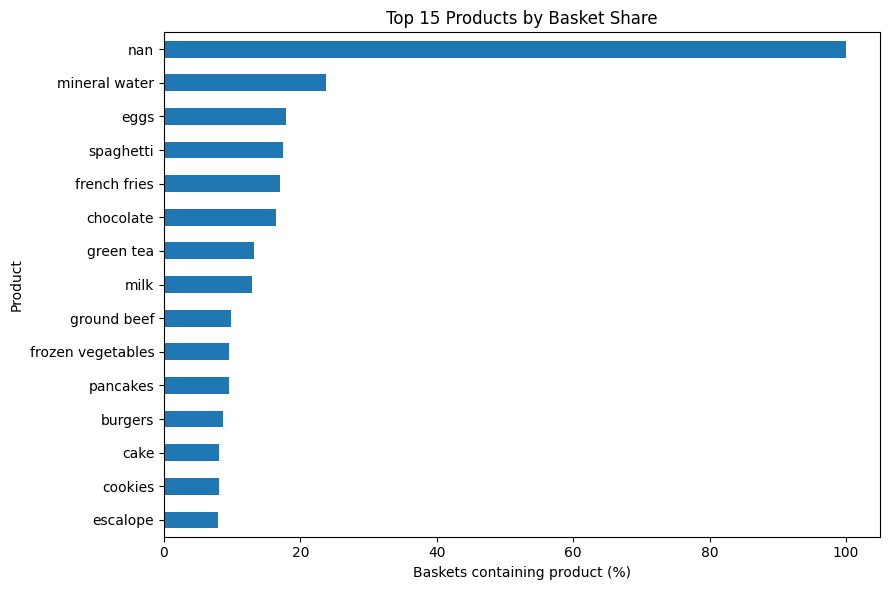

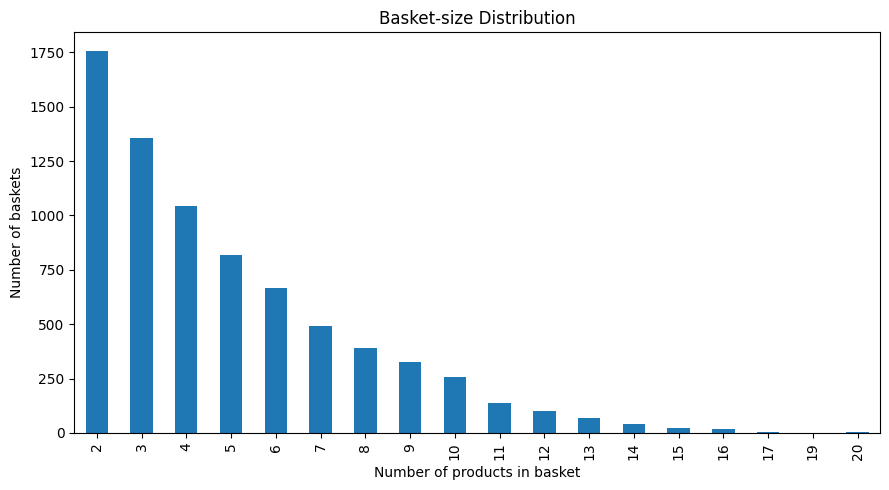

In [3]:
# Clean basket entries and create a binary basket-product matrix.
baskets = []
for _, row in retail.iterrows():
    items = [str(v).strip().lower() for v in row.tolist() if str(v).strip()]
    baskets.append(sorted(set(items)))

basket_sizes = np.array([len(b) for b in baskets])
products = sorted({item for basket in baskets for item in basket})
basket_matrix = np.zeros((len(baskets), len(products)), dtype=np.uint8)
product_to_col = {p: i for i, p in enumerate(products)}
for i, basket in enumerate(baskets):
    for item in basket:
        basket_matrix[i, product_to_col[item]] = 1
basket_df = pd.DataFrame(basket_matrix, columns=products)

product_counts = basket_df.sum().sort_values(ascending=False)
product_percent = 100 * product_counts / len(basket_df)
summary = pd.DataFrame({
    "Metric": ["Baskets", "Distinct products", "Basket-product entries",
               "Mean basket size", "Std basket size", "Median basket size",
               "Q1 basket size", "Q3 basket size", "Single-item baskets (%)",
               "Baskets with 8+ items (%)"],
    "Value": [len(baskets), len(products), int(basket_matrix.sum()),
              basket_sizes.mean(), basket_sizes.std(ddof=1), np.median(basket_sizes),
              np.percentile(basket_sizes, 25), np.percentile(basket_sizes, 75),
              100*np.mean(basket_sizes == 1), 100*np.mean(basket_sizes >= 8)]
})
display(summary.round(3))
summary.to_csv(f"{OUTPUT_DIR}/retail_summary.csv", index=False)
freq = pd.DataFrame({"Product": product_counts.index,
                     "Basket count": product_counts.values,
                     "Basket share (%)": product_percent.values})
display(freq.head(15).round(3))
freq.to_csv(f"{OUTPUT_DIR}/retail_product_frequencies.csv", index=False)
pd.DataFrame({"Basket size": basket_sizes}).to_csv(f"{OUTPUT_DIR}/retail_basket_sizes.csv", index=False)

freq.head(15).sort_values("Basket share (%)").plot(
    x="Product", y="Basket share (%)", kind="barh", figsize=(9, 6),
    legend=False, title="Top 15 Products by Basket Share")
plt.xlabel("Baskets containing product (%)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/retail_top_products.png", dpi=200)
plt.show()

pd.Series(basket_sizes).value_counts().sort_index().plot(
    kind="bar", figsize=(9, 5), title="Basket-size Distribution")
plt.xlabel("Number of products in basket")
plt.ylabel("Number of baskets")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/retail_basket_size_distribution.png", dpi=200)
plt.show()


## 3. Association rules: support, confidence and lift

Support measures the proportion of baskets containing both products; confidence measures the conditional frequency; lift compares co-occurrence against independent occurrence. These are descriptive associations, not causal effects.

In [4]:
# Pairwise association measures. These describe co-occurrence, not causation.
n = len(basket_df)
min_support_count = int(np.ceil(0.01 * n))
eligible = product_counts[product_counts >= min_support_count].index.tolist()
assoc = basket_df[eligible]
rows = []
for a in eligible:
    a_count = int(assoc[a].sum())
    for b in eligible:
        if a == b:
            continue
        b_count = int(assoc[b].sum())
        joint = int(((assoc[a] == 1) & (assoc[b] == 1)).sum())
        if joint >= 75 and a_count and b_count:
            confidence = joint / a_count
            rows.append((a, b, joint, joint/n, confidence, confidence/(b_count/n)))
rules = pd.DataFrame(rows, columns=[
    "If basket has", "Then also", "Joint baskets", "Support", "Confidence", "Lift"])
rules = rules.sort_values(["Lift", "Confidence"], ascending=False)
display(rules.head(20).round(4))
rules.to_csv(f"{OUTPUT_DIR}/retail_association_rules.csv", index=False)


,If basket has,Then also,Joint baskets,Support,Confidence,Lift
425,herb & pepper,ground beef,120,0.0160,0.3235,3.2920
263,ground beef,herb & pepper,120,0.0160,0.1628,3.2920
359,tomatoes,frozen vegetables,121,0.0161,0.2359,2.4745
278,frozen vegetables,tomatoes,121,0.0161,0.1692,2.4745
347,shrimp,frozen vegetables,125,0.0167,0.2332,2.4466
277,frozen vegetables,shrimp,125,0.0167,0.1748,2.4466
420,soup,milk,114,0.0152,0.3008,2.3212
247,milk,soup,114,0.0152,0.1173,2.3212
360,tomatoes,shrimp,84,0.0112,0.1637,2.2915
349,shrimp,tomatoes,84,0.0112,0.1567,2.2915


## 4. PCA and clustering

The clustering comparison uses a reproducible sample of up to 2,000 baskets. Silhouette and Davies–Bouldin scores are sensitive to the representation and parameters; weak scores indicate overlapping groups.

,Component,Variance explained,Cumulative variance
0,1,0.0668,0.0668
1,2,0.0440,0.1108
2,3,0.0417,0.1526
3,4,0.0408,0.1934
4,5,0.0362,0.2296
5,6,0.0327,0.2623
6,7,0.0308,0.2931
7,8,0.0246,0.3177
8,9,0.0240,0.3417
9,10,0.0232,0.3650


First two components variance (%): [6.68 4.4 ]
Cumulative variance first 10 components (%): 36.5


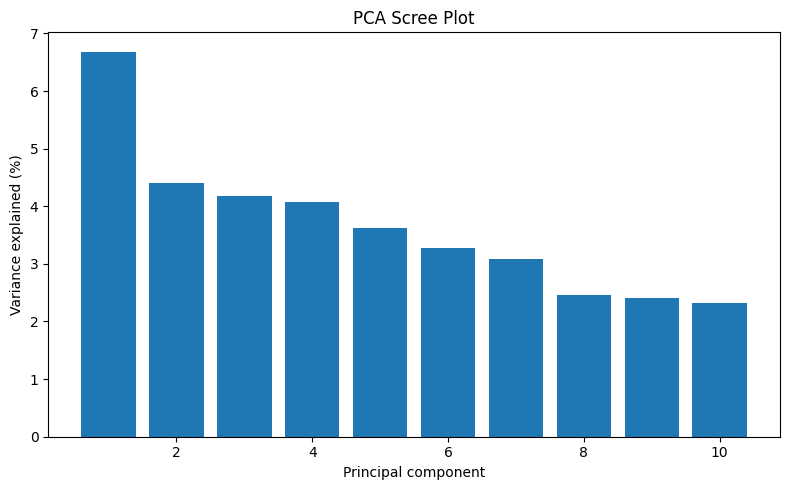

,k,Silhouette,Davies-Bouldin
0,2,0.1224,3.5190
1,3,0.0999,3.3053
2,4,0.0594,3.1944
3,5,0.0506,3.0858
4,6,0.0493,3.2617
5,7,0.0538,3.1618
6,8,0.0445,3.0100


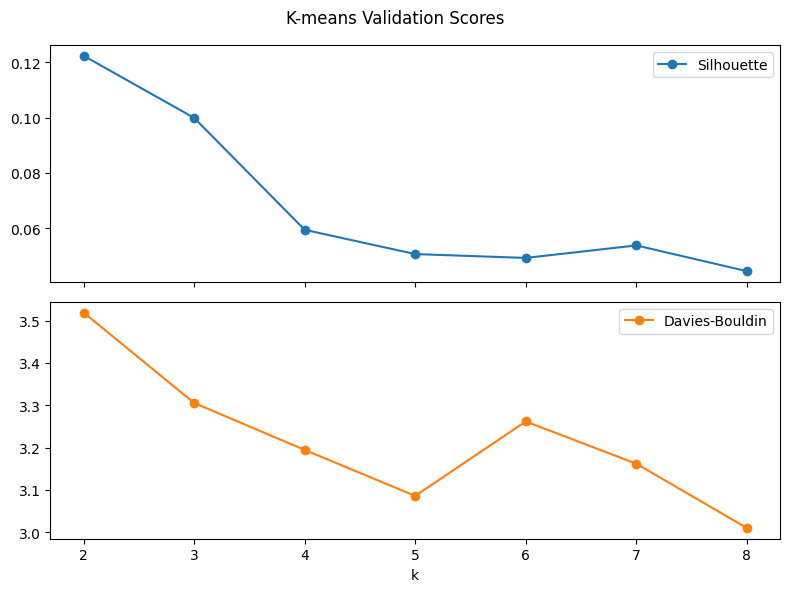

,Method,Clusters excluding noise,Silhouette,Davies-Bouldin
0,K-means (k=5),5,0.0506,3.0858
1,"Hierarchical (complete, k=5)",5,0.0744,4.9159
2,Spectral (k=5),5,-0.0128,3.0730
3,DBSCAN,1,NaN,NaN


DBSCAN noise points: 292 out of 2000


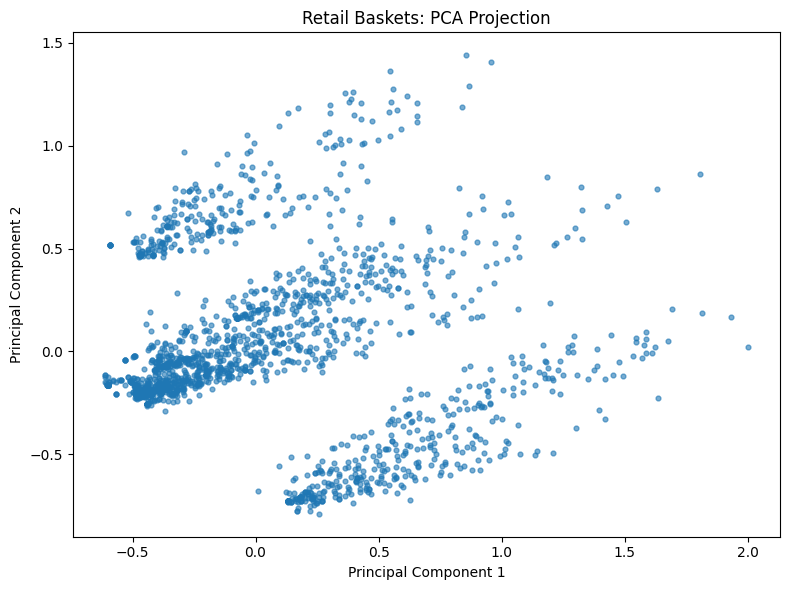

In [5]:
# PCA and clustering on a reproducible sample of up to 2,000 baskets.
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances

rng = np.random.RandomState(RANDOM_STATE)
sample_n = min(2000, len(basket_df))
idx = rng.choice(len(basket_df), sample_n, replace=False)
X = basket_df.iloc[idx].to_numpy()

pca = PCA(random_state=RANDOM_STATE)
Xp = pca.fit_transform(X)
pca_table = pd.DataFrame({
    "Component": np.arange(1, len(pca.explained_variance_ratio_)+1),
    "Variance explained": pca.explained_variance_ratio_,
    "Cumulative variance": np.cumsum(pca.explained_variance_ratio_)
})
display(pca_table.head(10).round(4))
pca_table.to_csv(f"{OUTPUT_DIR}/retail_pca_variance.csv", index=False)
print("First two components variance (%):", (pca.explained_variance_ratio_[:2]*100).round(2))
print("Cumulative variance first 10 components (%):", round(pca.explained_variance_ratio_[:10].sum()*100, 2))
plt.figure(figsize=(8, 5))
plt.bar(range(1, min(10, len(pca.explained_variance_ratio_))+1),
        pca.explained_variance_ratio_[:10]*100)
plt.xlabel("Principal component"); plt.ylabel("Variance explained (%)")
plt.title("PCA Scree Plot"); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/retail_pca_scree.png", dpi=200); plt.show()

km_results = []
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    km_results.append((k, silhouette_score(X, labels), davies_bouldin_score(X, labels)))
km_df = pd.DataFrame(km_results, columns=["k", "Silhouette", "Davies-Bouldin"])
display(km_df.round(4))
km_df.to_csv(f"{OUTPUT_DIR}/retail_kmeans_validation.csv", index=False)
km_df.set_index("k")[["Silhouette", "Davies-Bouldin"]].plot(
    marker="o", subplots=True, figsize=(8, 6), title="K-means Validation Scores")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/retail_kmeans_validation.png", dpi=200); plt.show()

cluster_models = {
    "K-means (k=5)": KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE),
    "Hierarchical (complete, k=5)": AgglomerativeClustering(n_clusters=5, linkage="complete"),
    "Spectral (k=5)": SpectralClustering(n_clusters=5, affinity="nearest_neighbors",
        n_neighbors=min(15, len(X)-1), random_state=RANDOM_STATE)
}
cluster_rows = []
for name, model in cluster_models.items():
    labels = model.fit_predict(X)
    cluster_rows.append((name, len(set(labels)), silhouette_score(X, labels),
                         davies_bouldin_score(X, labels)))

D = pairwise_distances(X, metric="jaccard")
db_labels = DBSCAN(eps=0.5, min_samples=5, metric="precomputed").fit_predict(D)
mask = db_labels != -1
db_clusters = len(set(db_labels[mask]))
db_silhouette = np.nan
if mask.sum() > 1 and db_clusters > 1:
    db_silhouette = silhouette_score(X[mask], db_labels[mask])
cluster_rows.append(("DBSCAN", db_clusters, db_silhouette, np.nan))
cluster_metrics = pd.DataFrame(cluster_rows, columns=[
    "Method", "Clusters excluding noise", "Silhouette", "Davies-Bouldin"])
display(cluster_metrics.round(4))
cluster_metrics.to_csv(f"{OUTPUT_DIR}/retail_clustering_metrics.csv", index=False)
print("DBSCAN noise points:", int((~mask).sum()), "out of", len(X))

plt.figure(figsize=(8, 6))
plt.scatter(Xp[:, 0], Xp[:, 1], s=12, alpha=0.6)
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.title("Retail Baskets: PCA Projection")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/retail_pca_projection.png", dpi=200); plt.show()


## 6. Generated tables and figures
The code cells above display the main summary tables and graphs inline when run. They also save the tables as CSV files and the figures as PNG files in the `outputs/` folder. Review these outputs alongside the report and only retain values that your run actually produces.

**Tables saved:** `retail_summary.csv`, `retail_product_frequencies.csv`, `retail_basket_sizes.csv`, `retail_association_rules.csv`, `retail_pca_variance.csv`, `retail_kmeans_validation.csv`, `retail_clustering_metrics.csv`.

**Figures saved:** `retail_top_products.png`, `retail_basket_size_distribution.png`, `retail_pca_scree.png`, `retail_kmeans_validation.png`, `retail_pca_projection.png`.

In [6]:
# Quick output inventory: shows which generated tables and figures exist after running earlier cells.
from pathlib import Path
output_files = sorted(Path(OUTPUT_DIR).glob('*'))
output_inventory = pd.DataFrame({
    'File': [p.name for p in output_files],
    'Type': ['Figure (PNG)' if p.suffix.lower() == '.png' else 'Table (CSV)' if p.suffix.lower() == '.csv' else p.suffix for p in output_files],
    'Size (bytes)': [p.stat().st_size for p in output_files],
})
display(output_inventory)


,File,Type,Size (bytes)
0,retail_association_rules.csv,Table (CSV),38291
1,retail_basket_size_distribution.png,Figure (PNG),56023
2,retail_basket_sizes.csv,Table (CSV),15668
3,retail_clustering_metrics.csv,Table (CSV),254
4,retail_kmeans_validation.csv,Table (CSV),313
5,retail_kmeans_validation.png,Figure (PNG),91361
6,retail_pca_projection.png,Figure (PNG),214911
7,retail_pca_scree.png,Figure (PNG),38537
8,retail_pca_variance.csv,Table (CSV),5207
9,retail_product_frequencies.csv,Table (CSV),3959


## 5. Interpretation and limitations

Use the generated outputs to discuss basket-size distribution, high-penetration products and pairs with elevated lift. The data has no customer identifiers, dates, prices or quantities, so it cannot support customer-level loyalty or revenue analysis. Re-run with the report's exact settings if exact numerical replication is required.